# Toronto Auto Theft — Data Modeling Notes

These notes turn the exploration results into a supervised modeling section. The written assumptions, constraints, findings, and technology list live in `Data_Modeling.md`. This notebook is the calculation behind that section.

The Toronto Police extract has **82,746 offence rows** and **31 columns**. Reports run from 1 January 2014 through 30 September 2026. Every row is UCR 2135 / 210, “Theft Of Motor Vehicle.” There is no recovery, arrest, or loss column. The label used below is constructed from `OCC_HOUR`.


## Why the label is the time of day

The professor’s suggestion was to predict when thefts happen, and to see which season has the most. Those are two different products:

- **Model.** Classify each reported theft into a six-hour occurrence band.
- **Count.** Total the occurrence months into Winter, Spring, Summer, and Autumn for 2014–2025.

Predicting place from the hour was set aside. Outside alone is 45,439 rows, about 55 percent, so a majority guess already looks strong. Neighbourhood has 158 classes, and the largest (West Humber-Clairville, 6,279 rows) is only about 7.6 percent of the file. Coordinates would also give the neighbourhood away. The “where at a given time” question is answered here with a premises-by-band table, which stays inside what reported counts can support.

| Band | Hours |
|---|---|
| Night | 0–5 |
| Morning | 6–11 |
| Afternoon | 12–17 |
| Evening | 18–23 |

Occurrence hour peaks at 22, the median is 16, and the standard deviation is 7.61. Evening contains the peak. A model that only barely beats “always predict the largest band” is still a valid result.


## Assumptions

1. The question is which six-hour band contains the occurrence hour of a reported auto theft.
2. The modeling unit is the offence row (`OBJECTID`). `EVENT_UNIQUE_ID` repeats on 7,432 occurrences, up to 20 rows each.
3. Features are premises type, division, occurrence weekday, season, and occurrence year. The label comes only from `OCC_HOUR`.
4. Report hour stays out. Its correlation with occurrence hour is 0.13.
5. Season is both a feature and a separate frequency table. Month, day-of-year, and `OCC_DATE` stay out so they cannot rebuild the season.
6. `NSA` stays as a category. Coordinate 0 is an unknown point and is not a feature.
7. The stratified 80/20 split describes other reports in this extract. It does not estimate a future year.
8. The encoder, the scaler, and mutual information are fit on the training rows only.
9. Class weights or resampling are used only if a training band is rare.
10. Figures are counts of reports, not rates per person or per vehicle.
11. The rise to 2023 and the later decline describe reported volume. The file cannot separate more theft from more reporting.

## Constraints

- One offence, from 1 January 2014 through 30 September 2026. The 2026 portion has 5,699 rows and stops at 30 September, so it is left out of season totals.
- Six rows have blank occurrence year, month, and weekday, with occurrence dates in 1969, 1978, 1990, and 1996. They are dropped.
- Weekday names are space-padded. The clock time on the date fields is midnight Eastern stored in UTC, not `OCC_HOUR`.
- Points are offset to the nearest intersection. 891 coordinates are 0, 931 neighbourhoods and 414 divisions are `NSA`, and 18 location types are blank.
- The 158-area and 140-area neighbourhood maps are different geographies. Code and name duplicate each other.
- Annual counts for Outside, House, Commercial, and Apartment move together (correlations 0.78 to 0.95). Twelve complete years are a thin sample for forecasting next year’s citywide total, and this model does not make that forecast.

## Technologies

Python, Pandas, NumPy, scikit-learn, Matplotlib, and Seaborn. Standardization is applied to `OCC_YEAR` because the classifier is logistic regression. A tree would not need that scaler.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

BAND_ORDER = ["Night", "Morning", "Afternoon", "Evening"]
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]
SEASON_BY_MONTH = {
    "December": "Winter", "January": "Winter", "February": "Winter",
    "March": "Spring", "April": "Spring", "May": "Spring",
    "June": "Summer", "July": "Summer", "August": "Summer",
    "September": "Autumn", "October": "Autumn", "November": "Autumn",
}
CAT_COLS = ["PREMISES_TYPE", "DIVISION", "OCC_DOW", "season"]
FEATURE_COLS = CAT_COLS + ["OCC_YEAR"]


def find_project_root():
    start = Path.cwd().resolve()
    for folder in [start, *start.parents]:
        matches = list((folder / "datasets").glob("Auto_Theft_Open_Data_*.csv"))
        if matches:
            return folder, matches[0]
    raise FileNotFoundError("Put the Auto Theft CSV in datasets/.")


project_root, csv_path = find_project_root()
print("Project:", project_root)
print("Source:", csv_path.name)


Project: G:\Git\toronto-auto-theft-analysis
Source: Auto_Theft_Open_Data_4481082360476864088(1).csv


## Load the extract

Confirm the file is the same one the exploration profiled: 82,746 rows, one offence, and report years 2014–2026.


In [2]:
df = pd.read_csv(csv_path, low_memory=False)
print("Rows, columns:", df.shape)
print("Offence:", df["OFFENCE"].unique().tolist())
print("UCR:", df["UCR_CODE"].unique().tolist(), "/", df["UCR_EXT"].unique().tolist())
print("Report years:", int(df["REPORT_YEAR"].min()), "to", int(df["REPORT_YEAR"].max()))
print("2026 rows:", int((df["REPORT_YEAR"] == 2026).sum()))
print("Blank occurrence parts:", int(df["OCC_YEAR"].isna().sum()))
print("Constant columns:", [col for col in df.columns if df[col].nunique(dropna=False) == 1])


Rows, columns: (82746, 31)
Offence: ['Theft Of Motor Vehicle']
UCR: [2135] / [210]
Report years: 2014 to 2026
2026 rows: 5699
Blank occurrence parts: 6
Constant columns: ['UCR_CODE', 'UCR_EXT', 'OFFENCE', 'CSI_CATEGORY']


## Transformations

Rules that do not learn from the data:

- Strip the padded weekday and month text.
- Drop the six rows with a blank occurrence year. Their dates are sentinels, not missing hours. `OCC_HOUR` is filled even on those rows, and they still leave the model because season and weekday cannot be built honestly from a 1969 or 1978 date.
- Map `OCC_HOUR` to the four bands with NumPy.
- Map `OCC_MONTH` to season. Any month that fails the map stops the notebook.
- Leave `NSA` as its own division category.
- Do not impute coordinates or neighbourhood. Neither is a feature. The 18 blank location types also stay out, because `LOCATION_TYPE` is not in the model.

Season totals use occurrence years 2014–2025 only. Rows from 2026, and the small number of occurrences dated before 2014, remain in the classifier when their month and weekday are present. A September 2026 row is a real autumn occurrence. It would bias a season *total*, because October–December 2026 are absent.


In [3]:
work = df.copy()
work["OCC_DOW"] = work["OCC_DOW"].str.strip()
work["OCC_MONTH"] = work["OCC_MONTH"].str.strip()

sentinels = work.loc[work["OCC_YEAR"].isna(), ["EVENT_UNIQUE_ID", "OCC_DATE", "REPORT_YEAR", "OCC_HOUR"]]
print("Sentinel rows dropped:")
print(sentinels.to_string(index=False))

model_df = work.dropna(subset=["OCC_YEAR", "OCC_MONTH", "OCC_DOW"]).copy()
model_df["OCC_YEAR"] = model_df["OCC_YEAR"].astype(int)
model_df["season"] = model_df["OCC_MONTH"].map(SEASON_BY_MONTH)
if model_df["season"].isna().any():
    missing = model_df.loc[model_df["season"].isna(), "OCC_MONTH"].unique()
    raise ValueError(f"Unmapped month names: {missing}")

hours = model_df["OCC_HOUR"].to_numpy()
bands = np.full(len(hours), "Evening", dtype=object)
bands[hours <= 17] = "Afternoon"
bands[hours <= 11] = "Morning"
bands[hours <= 5] = "Night"
model_df["time_band"] = bands

print("Modeling rows:", len(model_df))
print("Occurrence years outside 2014-2025:", int((~model_df["OCC_YEAR"].between(2014, 2025)).sum()))
print(model_df["time_band"].value_counts().reindex(BAND_ORDER).to_string())


Sentinel rows dropped:
EVENT_UNIQUE_ID             OCC_DATE  REPORT_YEAR  OCC_HOUR
 GO-20141947935 4/10/1978 4:00:00 AM         2014         0
 GO-20161667005  1/1/1996 5:00:00 AM         2016         0
 GO-20161667005  1/1/1996 5:00:00 AM         2016         0
 GO-20211617261 8/10/1990 4:00:00 AM         2021        12
 GO-20252630792  6/6/1969 4:00:00 AM         2025        14
 GO-20252630792  6/6/1969 4:00:00 AM         2025        14
Modeling rows: 82740
Occurrence years outside 2014-2025: 5680
time_band
Night        17673
Morning      11473
Afternoon    17225
Evening      36369


## Which season has the most reported thefts

Counts use the occurrence month and occurrence years 2014 through 2025. September was the busiest single month in the exploration. The season total can still differ, because a season is three months.


        records  percent
season                  
Winter    17846     23.2
Spring    18767     24.4
Summer    19494     25.3
Autumn    20953     27.2
Busiest season: Autumn 20953


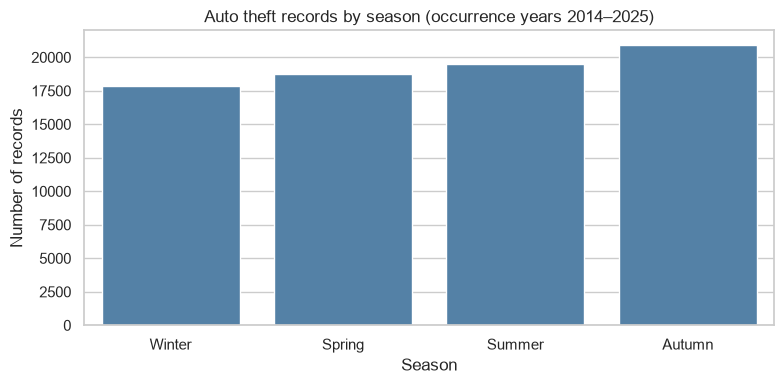

In [4]:
season_base = model_df.loc[model_df["OCC_YEAR"].between(2014, 2025)]
season_counts = (
    season_base["season"].value_counts().reindex(SEASON_ORDER).rename("records").astype(int)
)
season_share = (season_counts / season_counts.sum() * 100).round(1)
season_table = pd.DataFrame({"records": season_counts, "percent": season_share})
print(season_table.to_string())
print("Busiest season:", season_counts.idxmax(), int(season_counts.max()))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=season_counts.index, y=season_counts.to_numpy(), color="steelblue", ax=ax)
ax.set_title("Auto theft records by season (occurrence years 2014–2025)")
ax.set_xlabel("Season")
ax.set_ylabel("Number of records")
fig.tight_layout()


## Where reports concentrate inside each time band

This is the place question, answered as a count. Each cell is the number of offence rows. The share row underneath shows the mix *within* that band, so a larger band does not automatically win every premises type.


Counts
PREMISES_TYPE  Apartment  Commercial  Educational  House  Other  Outside  Transit
time_band                                                                        
Night                639        1501           16   7866    691     6951        9
Morning              430        1242           28   2041    264     7282      186
Afternoon            589        2138           23   2196    359    11864       56
Evening             1132        1892           39  12792   1143    19339       32

Percent of each time band
PREMISES_TYPE  Apartment  Commercial  Educational  House  Other  Outside  Transit
time_band                                                                        
Night                3.6         8.5          0.1   44.5    3.9     39.3      0.1
Morning              3.7        10.8          0.2   17.8    2.3     63.5      1.6
Afternoon            3.4        12.4          0.1   12.7    2.1     68.9      0.3
Evening              3.1         5.2          0.1   35.2    3.1 

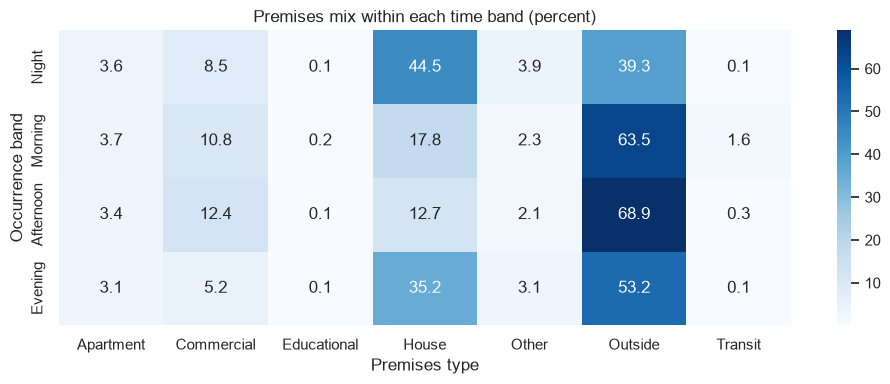

In [5]:
premises_counts = pd.crosstab(model_df["time_band"], model_df["PREMISES_TYPE"]).reindex(BAND_ORDER)
premises_share = (premises_counts.div(premises_counts.sum(axis=1), axis=0) * 100).round(1)
print("Counts")
print(premises_counts.to_string())
print("\nPercent of each time band")
print(premises_share.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(premises_share, annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set_title("Premises mix within each time band (percent)")
ax.set_xlabel("Premises type")
ax.set_ylabel("Occurrence band")
fig.tight_layout()


## Feature selection

Pandas removes columns before any score is computed.

- Identifiers: `OBJECTID`, `EVENT_UNIQUE_ID`.
- Constants: `UCR_CODE`, `UCR_EXT`, `OFFENCE`, `CSI_CATEGORY`.
- The label’s own source: `OCC_HOUR`.
- Copies of season: `OCC_MONTH`, `OCC_DOY`, `OCC_DATE`.
- The reporting clock and the report calendar.
- Location type, both neighbourhood maps, and both coordinate pairs.

Five columns remain. `mutual_info_classif` ranks them on the **training** rows. That score is the information-gain measure for a categorical label. Categories are integer codes and marked discrete. Year stays numeric. A score near zero is a column to drop. A low score on a one-hot dummy would be a different decision, so the rank is computed on the original columns.


Share of modeling rows in each band (percent):
time_band
Night        21.4
Morning      13.9
Afternoon    20.8
Evening      44.0

Training share by band:
Night        0.214
Morning      0.139
Afternoon    0.208
Evening      0.440
Smallest training band is 13.9%. Class weights are reserved for a band under 5%: False



Mutual information with time band (training rows):
PREMISES_TYPE    0.0444
DIVISION         0.0059
OCC_YEAR         0.0054
OCC_DOW          0.0024
season           0.0004
Kept features: ['PREMISES_TYPE', 'DIVISION', 'OCC_YEAR', 'OCC_DOW']


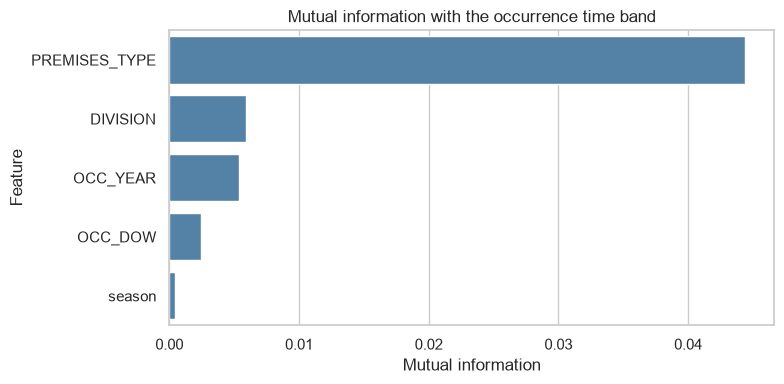

In [6]:
band_share = (
    model_df["time_band"].value_counts(normalize=True).reindex(BAND_ORDER).mul(100).round(1)
)
print("Share of modeling rows in each band (percent):")
print(band_share.to_string())

y = model_df["time_band"].to_numpy()
event_ids = model_df["EVENT_UNIQUE_ID"].to_numpy()
indices = np.arange(len(model_df))
idx_train, idx_test = train_test_split(
    indices, test_size=0.2, random_state=42, stratify=y
)

X_train = model_df.iloc[idx_train][FEATURE_COLS].copy()
X_test = model_df.iloc[idx_test][FEATURE_COLS].copy()
y_train = y[idx_train]
y_test = y[idx_test]

train_share = pd.Series(y_train).value_counts(normalize=True).reindex(BAND_ORDER)
print("\nTraining share by band:")
print(train_share.round(3).to_string())
rare_cutoff = 0.05
rare_band = bool(train_share.min() < rare_cutoff)
print(
    f"Smallest training band is {train_share.min():.1%}. "
    f"Class weights are reserved for a band under {rare_cutoff:.0%}: {rare_band}"
)

coded = pd.DataFrame(index=X_train.index)
for column in CAT_COLS:
    coded[column] = pd.factorize(X_train[column])[0]
coded["OCC_YEAR"] = X_train["OCC_YEAR"].to_numpy()
discrete_mask = np.array([True, True, True, True, False])
mi_scores = mutual_info_classif(
    coded.to_numpy(),
    y_train,
    discrete_features=discrete_mask,
    random_state=42,
)
mi_table = (
    pd.Series(mi_scores, index=FEATURE_COLS, name="mutual_information")
    .sort_values(ascending=False)
    .round(4)
)
print("\nMutual information with time band (training rows):")
print(mi_table.to_string())
kept_features = mi_table[mi_table >= 0.001].index.tolist()
print("Kept features:", kept_features)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=mi_table.to_numpy(), y=mi_table.index, color="steelblue", ax=ax)
ax.set_title("Mutual information with the occurrence time band")
ax.set_xlabel("Mutual information")
ax.set_ylabel("Feature")
fig.tight_layout()


## Train, test, and class balance

The split above is an 80/20 `train_test_split` on a NumPy index, stratified on the band, with `random_state=42`.

A band counts as rare only when it is under 5 percent of the training rows. Morning is the smallest band and is still more than a tenth of the rows, so the reported model leaves the class weights alone. The notebook also fits a `class_weight="balanced"` version and prints it beside the dummy, because that check is what shows whether reweighting helps. SMOTE stays out either way. The inputs are categories, and a synthetic row would be a fractional mix of divisions and weekdays.

Logistic regression uses the scaled year, so `StandardScaler` is fit inside a pipeline on the training fold only. `OneHotEncoder(handle_unknown="ignore")` does the same for categories. The comparison model is `DummyClassifier(strategy="most_frequent")`.

The same police occurrence can contribute several rows. The stratified split does not keep those rows together. The overlap count below is a constraint on how independent the test rows are. It does not change the split the section requires.


Features in the classifier: ['PREMISES_TYPE', 'DIVISION', 'OCC_YEAR', 'OCC_DOW']
class_weight: None


Logistic regression accuracy: 0.442
Majority-class dummy accuracy: 0.440
Gap over the dummy: 0.002
Balanced-weight accuracy, for comparison: 0.292
Dummy always predicts: Evening
              precision  recall  f1-score    support
Night             0.307   0.014     0.027   3534.000
Morning           0.500   0.011     0.022   2295.000
Afternoon         0.314   0.098     0.149   3445.000
Evening           0.452   0.948     0.612   7274.000
accuracy          0.442   0.442     0.442      0.442
macro avg         0.393   0.268     0.203  16548.000
weighted avg      0.399   0.442     0.309  16548.000


Test rows whose occurrence id also appears in training: 2456
Test rows: 16548


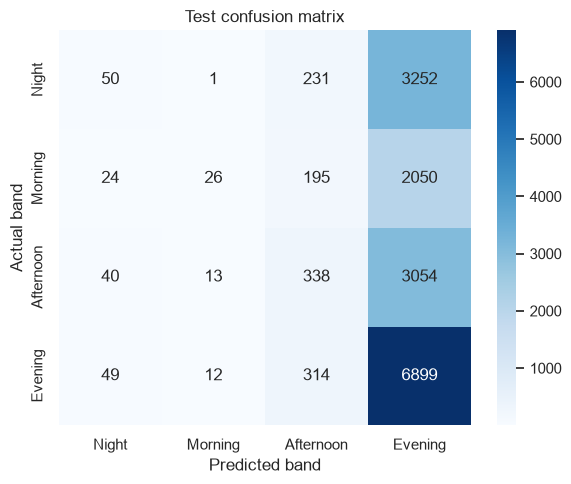

In [7]:
model_features = kept_features
model_cat_cols = [column for column in model_features if column in CAT_COLS]
print("Features in the classifier:", model_features)
print("class_weight:", "balanced" if rare_band else None)

def make_pipeline(class_weight):
    preprocess = ColumnTransformer(
        transformers=[
            ("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), model_cat_cols),
            ("year", StandardScaler(), ["OCC_YEAR"]),
        ]
    )
    return Pipeline(
        steps=[
            ("preprocess", preprocess),
            (
                "classifier",
                LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=42),
            ),
        ]
    )

model = make_pipeline("balanced" if rare_band else None)
model.fit(X_train[model_features], y_train)
predictions = model.predict(X_test[model_features])

balanced = make_pipeline("balanced")
balanced.fit(X_train[model_features], y_train)
balanced_accuracy = accuracy_score(y_test, balanced.predict(X_test[model_features]))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_predictions = dummy.predict(X_test)

model_accuracy = accuracy_score(y_test, predictions)
dummy_accuracy = accuracy_score(y_test, dummy_predictions)
print(f"Logistic regression accuracy: {model_accuracy:.3f}")
print(f"Majority-class dummy accuracy: {dummy_accuracy:.3f}")
print(f"Gap over the dummy: {model_accuracy - dummy_accuracy:.3f}")
print(f"Balanced-weight accuracy, for comparison: {balanced_accuracy:.3f}")
print("Dummy always predicts:", dummy_predictions[0])

report = classification_report(
    y_test, predictions, labels=BAND_ORDER, output_dict=True, zero_division=0
)
print(pd.DataFrame(report).T.round(3).to_string())

matrix = confusion_matrix(y_test, predictions, labels=BAND_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    matrix, annot=True, fmt="d", cmap="Blues",
    xticklabels=BAND_ORDER, yticklabels=BAND_ORDER, ax=ax,
)
ax.set_title("Test confusion matrix")
ax.set_xlabel("Predicted band")
ax.set_ylabel("Actual band")
fig.tight_layout()

shared_events = np.isin(event_ids[idx_test], event_ids[idx_train]).sum()
print("Test rows whose occurrence id also appears in training:", int(shared_events))
print("Test rows:", len(idx_test))


## How to read the result

Report the season total and the premises mix as descriptions of the reports. Report the classifier against the dummy, not against 100 percent.

- A busiest season is the largest bar in the season chart. It answers “when in the year,” and it is not a prediction.
- The heatmap answers “where, at a given time” as the premises mix inside each band. Outside can dominate every band and still leave a shift toward House or Commercial in one of them. That shift is the place finding.
- Mutual information ranks which of the five features reduces uncertainty about the band. Premises type is the feature most likely to lead. Year should matter less, because the hourly pattern is not the same thing as the 2023 volume peak.
- Accuracy close to the dummy means the hour is mostly a citywide pattern, which matches the exploration: premises types rise and fall together across years, and occurrence hour is widely spread.
- Precision and recall by band matter more than a single accuracy. The confusion matrix shows which bands the model swaps, usually neighbours on the clock.
- Test rows that share an `EVENT_UNIQUE_ID` with the training set make the test a little easier than a fully new occurrence. Quote that overlap next to the accuracy.

What this notebook does not claim: a probability that a particular corner will be hit, a rate per parked car, or a forecast of next year’s citywide total.
